In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)
from xgboost import XGBClassifier
from scipy.stats import wasserstein_distance

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")

In [ ]:
uploaded = files.upload()

Saving train.csv to train.csv


In [ ]:
df = pd.read_csv("train.csv")

print("Shape:", df.shape)
print(df.columns.tolist())

Shape: (480000, 15)
[' Flow Duration', ' Fwd Packet Length Std', ' Flow Packets/s', ' Flow IAT Mean', ' Fwd Header Length', ' Packet Length Mean', ' Packet Length Std', ' Packet Length Variance', ' ACK Flag Count', 'Subflow Fwd Packets', ' Subflow Fwd Bytes', 'Init_Win_bytes_forward', ' act_data_pkt_fwd', ' min_seg_size_forward', ' Label']


In [ ]:
df["Label"] = df[" Label"].str.strip()

df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna()

print(df.shape)
print(df["Label"].value_counts())

(480000, 16)
Label
DrDoS_MSSQL      40082
BENIGN           40048
DrDoS_LDAP       40042
UDP-lag          40037
DrDoS_NTP        40012
DrDoS_NetBIOS    40012
TFTP             40012
DrDoS_SSDP       39994
DrDoS_UDP        39966
DrDoS_SNMP       39965
Syn              39930
DrDoS_DNS        39900
Name: count, dtype: int64


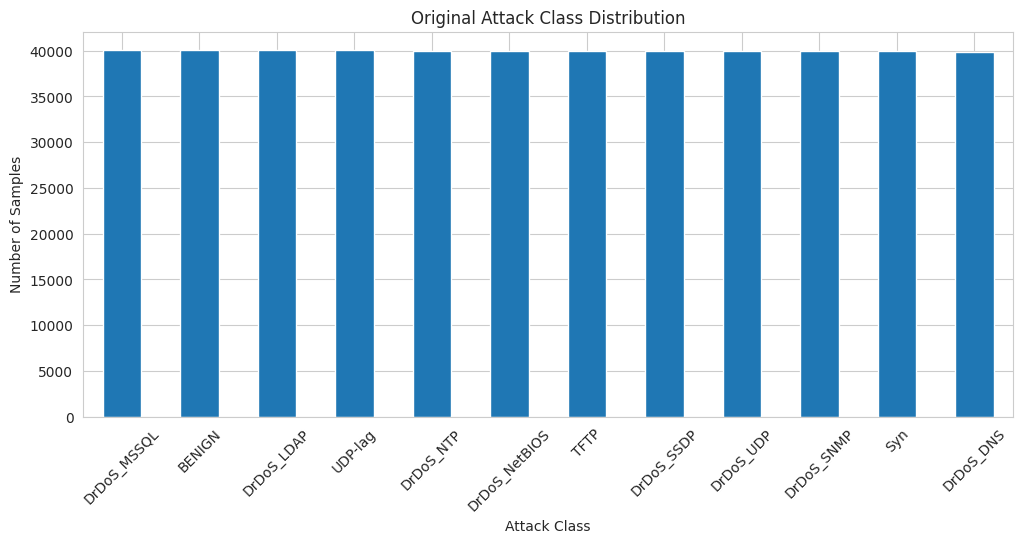

In [ ]:
plt.figure(figsize=(12,5))

df["Label"].value_counts().plot(kind="bar")

plt.title("Original Attack Class Distribution")
plt.xlabel("Attack Class")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45)
plt.show()

In [ ]:
data = []

for label in df["Label"].unique():
    temp = df[df["Label"] == label]
    data.append(temp.sample(4000, random_state=42))

data = pd.concat(data)
data = data.sample(frac=1, random_state=42).reset_index(drop=True)

print(data.shape)
print(data["Label"].value_counts())

(48000, 16)
Label
Syn              4000
DrDoS_NetBIOS    4000
TFTP             4000
UDP-lag          4000
DrDoS_UDP        4000
DrDoS_DNS        4000
DrDoS_MSSQL      4000
DrDoS_SNMP       4000
DrDoS_SSDP       4000
DrDoS_LDAP       4000
BENIGN           4000
DrDoS_NTP        4000
Name: count, dtype: int64


In [ ]:
features = [c for c in data.columns if c != "Label"]

X = data[features]

y = data["Label"].apply(
    lambda x: 0 if x == "BENIGN" else 1
)

print("Features:", len(features))
print("Target distribution:")
print(y.value_counts())
# Check which columns contain text
print(data.dtypes)

Features: 15
Target distribution:
Label
1    44000
0     4000
Name: count, dtype: int64
 Flow Duration               int64
 Fwd Packet Length Std     float64
 Flow Packets/s            float64
 Flow IAT Mean             float64
 Fwd Header Length           int64
 Packet Length Mean        float64
 Packet Length Std         float64
 Packet Length Variance    float64
 ACK Flag Count              int64
Subflow Fwd Packets          int64
 Subflow Fwd Bytes           int64
Init_Win_bytes_forward       int64
 act_data_pkt_fwd            int64
 min_seg_size_forward        int64
 Label                      object
Label                       object
dtype: object


In [ ]:
# Keep only numerical features
features = data.select_dtypes(include=np.number).columns.tolist()

X = data[features]

y = data["Label"].apply(
    lambda x: 0 if x == "BENIGN" else 1
)

print("Number of features:", len(features))
print(features)

Number of features: 14
[' Flow Duration', ' Fwd Packet Length Std', ' Flow Packets/s', ' Flow IAT Mean', ' Fwd Header Length', ' Packet Length Mean', ' Packet Length Std', ' Packet Length Variance', ' ACK Flag Count', 'Subflow Fwd Packets', ' Subflow Fwd Bytes', 'Init_Win_bytes_forward', ' act_data_pkt_fwd', ' min_seg_size_forward']


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
def get_models():
    rf = RandomForestClassifier(
        n_estimators=150,
        random_state=42,
        n_jobs=-1
    )

    xgb = XGBClassifier(
        n_estimators=150,
        max_depth=6,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )

    return rf, xgb

In [ ]:
rf, xgb = get_models()

rf_result, rf_pred, rf_prob = evaluate(
    rf, X_train, X_test, y_train, y_test
)

xgb_result, xgb_pred, xgb_prob = evaluate(
    xgb, X_train, X_test, y_train, y_test
)

results_a = pd.DataFrame(
    [rf_result, xgb_result],
    index=["Random Forest", "XGBoost"]
)

results_a

,Accuracy,Precision,Recall,F1,ROC-AUC,Train Time,Test Time
Random Forest,1.000000,1.0,1.000000,1.000000,1.0,5.111903,0.160154
XGBoost,0.999792,1.0,0.999773,0.999886,1.0,0.683197,0.065271


EXP->B

In [ ]:
attacks = [x for x in data["Label"].unique() if x != "BENIGN"]

print("Number of attack types:", len(attacks))
print(attacks)

Number of attack types: 11
['Syn', 'DrDoS_NetBIOS', 'TFTP', 'UDP-lag', 'DrDoS_UDP', 'DrDoS_DNS', 'DrDoS_MSSQL', 'DrDoS_SNMP', 'DrDoS_SSDP', 'DrDoS_LDAP', 'DrDoS_NTP']


In [ ]:
unseen_results = []

for attack in attacks:

    train_data = data[data["Label"] != attack]

    benign_test = data[data["Label"] == "BENIGN"].sample(
        1000, random_state=42
    )

    attack_test = data[data["Label"] == attack]

    test_data = pd.concat([benign_test, attack_test])

    X_tr = train_data[features]
    y_tr = train_data["Label"].apply(
        lambda x: 0 if x == "BENIGN" else 1
    )

    X_te = test_data[features]
    y_te = test_data["Label"].apply(
        lambda x: 0 if x == "BENIGN" else 1
    )

    rf, xgb = get_models()

    rf_res, _, _ = evaluate(rf, X_tr, X_te, y_tr, y_te)
    xgb_res, _, _ = evaluate(xgb, X_tr, X_te, y_tr, y_te)

    unseen_results.append({
        "Attack": attack,
        "RF Recall": rf_res["Recall"],
        "RF F1": rf_res["F1"],
        "XGB Recall": xgb_res["Recall"],
        "XGB F1": xgb_res["F1"]
    })

unseen_results = pd.DataFrame(unseen_results)

unseen_results

,Attack,RF Recall,RF F1,XGB Recall,XGB F1
0,Syn,0.9995,0.999750,0.99950,0.999750
1,DrDoS_NetBIOS,0.9990,0.999500,0.99900,0.999500
2,TFTP,1.0000,1.000000,1.00000,1.000000
3,UDP-lag,0.9995,0.999750,1.00000,1.000000
4,DrDoS_UDP,1.0000,1.000000,0.99975,0.999875
5,DrDoS_DNS,0.9980,0.998999,0.99075,0.995354
6,DrDoS_MSSQL,1.0000,1.000000,1.00000,1.000000
7,DrDoS_SNMP,1.0000,1.000000,1.00000,1.000000
8,DrDoS_SSDP,1.0000,1.000000,1.00000,1.000000
9,DrDoS_LDAP,1.0000,1.000000,0.99975,0.999875


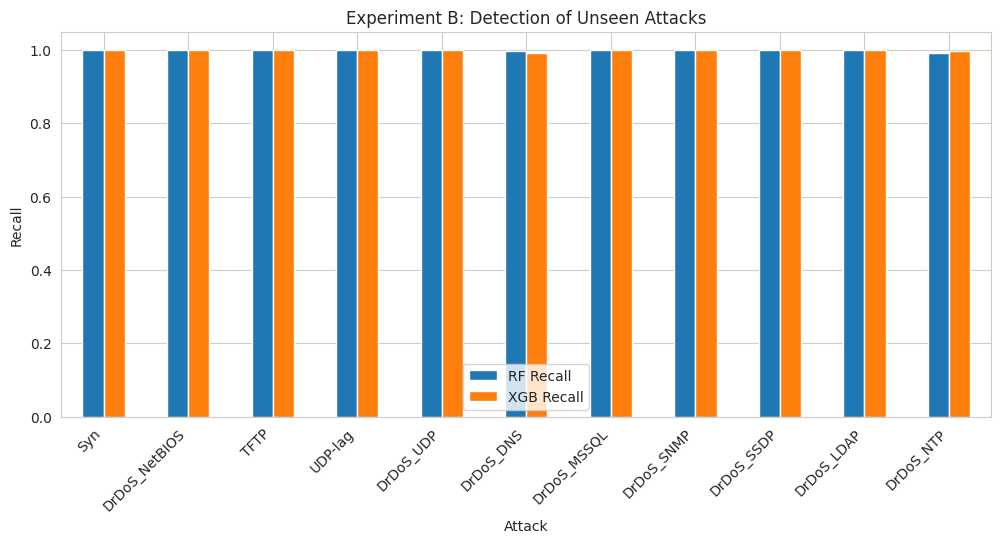

In [ ]:
unseen_results.plot(
    x="Attack",
    y=["RF Recall", "XGB Recall"],
    kind="bar",
    figsize=(12, 5)
)

plt.title("Experiment B: Detection of Unseen Attacks")
plt.ylabel("Recall")
plt.ylim(0, 1.05)
plt.xticks(rotation=45, ha="right")
plt.show()

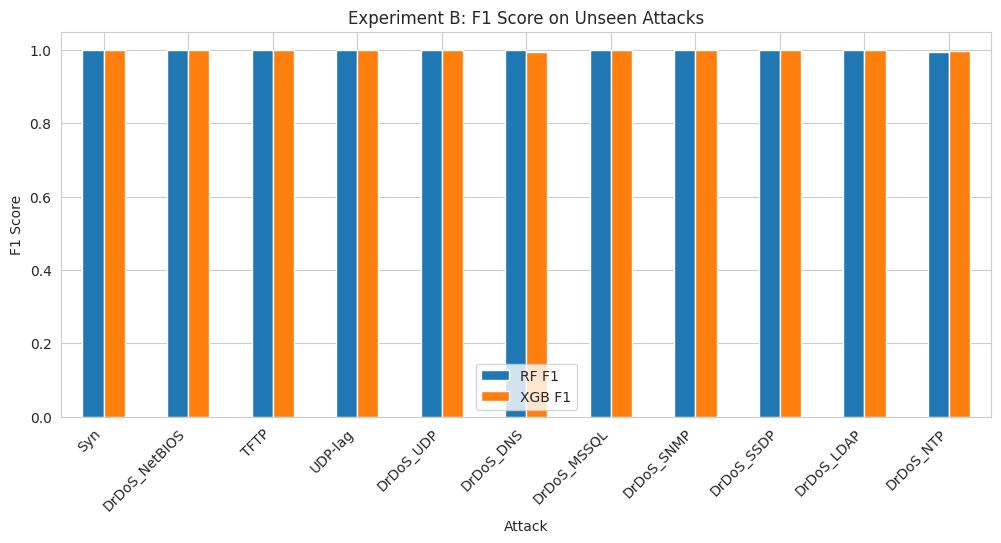

In [ ]:
unseen_results.plot(
    x="Attack",
    y=["RF F1", "XGB F1"],
    kind="bar",
    figsize=(12, 5)
)

plt.title("Experiment B: F1 Score on Unseen Attacks")
plt.ylabel("F1 Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=45, ha="right")
plt.show()

In [ ]:
progressive_results = []

for count in [1, 3, 5, 7]:

    for seed in range(10):

        rng = np.random.RandomState(seed)
        hidden = list(rng.choice(attacks, count, replace=False))

        train_data = data[~data["Label"].isin(hidden)]

        benign_test = data[data["Label"] == "BENIGN"].sample(
            1000, random_state=42
        )

        attack_test = data[data["Label"].isin(hidden)]

        test_data = pd.concat([benign_test, attack_test])

        X_tr = train_data[features]
        y_tr = train_data["Label"].apply(
            lambda x: 0 if x == "BENIGN" else 1
        )

        X_te = test_data[features]
        y_te = test_data["Label"].apply(
            lambda x: 0 if x == "BENIGN" else 1
        )

        rf, xgb = get_models()

        rf_res, _, _ = evaluate(
            rf, X_tr, X_te, y_tr, y_te
        )

        xgb_res, _, _ = evaluate(
            xgb, X_tr, X_te, y_tr, y_te
        )

        progressive_results.append({
            "Hidden Attacks": count,
            "Seed": seed,
            "Hidden Set": ", ".join(hidden),
            "RF Recall": rf_res["Recall"],
            "RF F1": rf_res["F1"],
            "XGB Recall": xgb_res["Recall"],
            "XGB F1": xgb_res["F1"]
        })

progressive_results = pd.DataFrame(progressive_results)

progressive_summary = progressive_results.groupby(
    "Hidden Attacks"
)[["RF Recall", "RF F1", "XGB Recall", "XGB F1"]].agg(
    ["mean", "std", "min", "max"]
)

progressive_summary

RF Recall                                   RF F1            \
                    mean       std       min       max      mean       std   
Hidden Attacks                                                               
1               0.999550  0.000832  0.998000  1.000000  0.999775  0.000416   
3               0.999483  0.000449  0.998667  1.000000  0.999742  0.000225   
5               0.975395  0.057622  0.818900  0.999700  0.986715  0.031585   
7               0.905025  0.132843  0.639429  0.999071  0.945191  0.079044   

                                   XGB Recall                                \
                     min       max       mean       std       min       max   
Hidden Attacks                                                                
1               0.998999  1.000000   0.998100  0.003875  0.990750  1.000000   
3               0.999333  1.000000   0.998742  0.001770  0.995833  1.000000   
5               0.900434  0.999850   0.995555  0.010395  0.966100  0.999900   
7               0.780063  0.999535   0.938696  0.113003  0.721071  0.998893   

                  XGB F1                                
                    mean       std       min       max  
Hidden Attacks                                          
1               0.999046  0.001947  0.995354  1.000000  
3               0.999370  0.000887  0.997912  1.000000  
5               0.997748  0.005290  0.982758  0.999950  
7               0.964937  0.065626  0.837933  0.999446

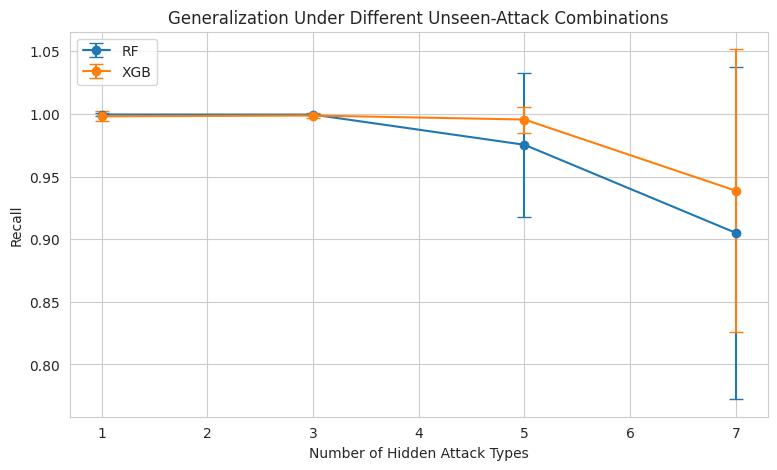

In [ ]:
summary = progressive_results.groupby("Hidden Attacks")[
    ["RF Recall", "XGB Recall"]
].agg(["mean", "std"])

plt.figure(figsize=(9, 5))

for model in ["RF", "XGB"]:
    mean = summary[(f"{model} Recall", "mean")]
    std = summary[(f"{model} Recall", "std")]

    plt.errorbar(
        mean.index,
        mean.values,
        yerr=std.values,
        marker="o",
        capsize=5,
        label=model
    )

plt.xlabel("Number of Hidden Attack Types")
plt.ylabel("Recall")
plt.title("Generalization Under Different Unseen-Attack Combinations")
plt.legend()
plt.grid(True)
plt.show()

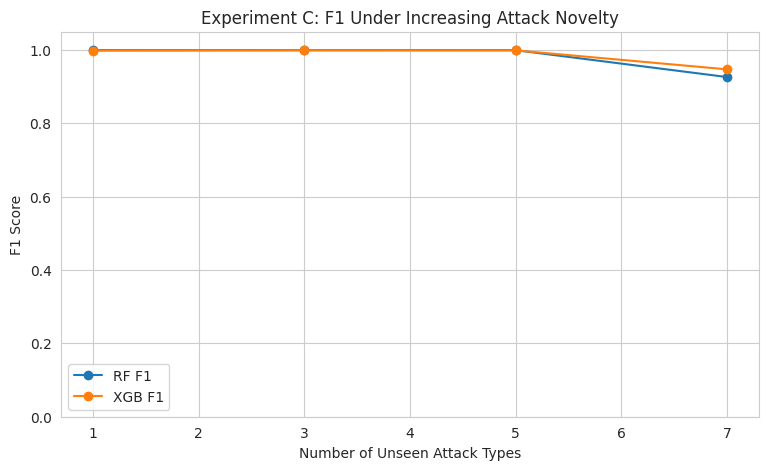

In [ ]:
progressive_avg[["RF F1", "XGB F1"]].plot(
    marker="o",
    figsize=(9, 5)
)

plt.title("Experiment C: F1 Under Increasing Attack Novelty")
plt.xlabel("Number of Unseen Attack Types")
plt.ylabel("F1 Score")
plt.ylim(0, 1.05)
plt.grid(True)
plt.show()

In [ ]:
novelty_results = []

for attack in attacks:

    seen = data[
        (data["Label"] != "BENIGN") &
        (data["Label"] != attack)
    ]

    unseen = data[data["Label"] == attack]

    distances = []

    for feature in features:

        seen_values = seen[feature].values
        unseen_values = unseen[feature].values

        scale = np.std(seen_values) + 1e-8

        distance = wasserstein_distance(
            seen_values, unseen_values
        ) / scale

        distances.append(distance)

    novelty_results.append({
        "Attack": attack,
        "Novelty": np.mean(distances)
    })

novelty = pd.DataFrame(novelty_results)

novelty

,Attack,Novelty
0,Syn,0.877150
1,DrDoS_NetBIOS,0.321059
2,TFTP,0.334803
3,UDP-lag,0.688317
4,DrDoS_UDP,0.355955
5,DrDoS_DNS,0.363076
6,DrDoS_MSSQL,0.327883
7,DrDoS_SNMP,0.389962
8,DrDoS_SSDP,0.351504
9,DrDoS_LDAP,0.389363


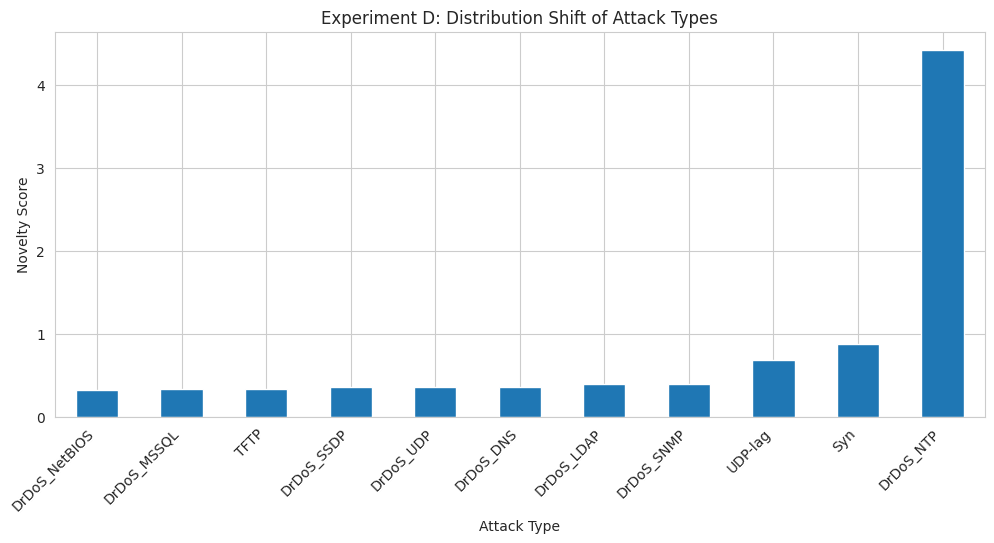

In [ ]:
novelty.sort_values("Novelty").plot(
    x="Attack",
    y="Novelty",
    kind="bar",
    figsize=(12, 5),
    legend=False
)

plt.title("Experiment D: Distribution Shift of Attack Types")
plt.ylabel("Novelty Score")
plt.xlabel("Attack Type")
plt.xticks(rotation=45, ha="right")
plt.show()

In [ ]:
baseline_rf_recall = results_a.loc["Random Forest", "Recall"]
baseline_xgb_recall = results_a.loc["XGBoost", "Recall"]

degradation = unseen_results.copy()

degradation["RF Degradation"] = (
    baseline_rf_recall - degradation["RF Recall"]
)

degradation["XGB Degradation"] = (
    baseline_xgb_recall - degradation["XGB Recall"]
)

degradation = degradation.merge(
    novelty,
    on="Attack"
)

degradation

,Attack,RF Recall,RF F1,XGB Recall,XGB F1,RF Degradation,XGB Degradation,Novelty
0,Syn,0.9995,0.999750,0.99950,0.999750,0.0005,0.000273,0.877150
1,DrDoS_NetBIOS,0.9990,0.999500,0.99900,0.999500,0.0010,0.000773,0.321059
2,TFTP,1.0000,1.000000,1.00000,1.000000,0.0000,-0.000227,0.334803
3,UDP-lag,0.9995,0.999750,1.00000,1.000000,0.0005,-0.000227,0.688317
4,DrDoS_UDP,1.0000,1.000000,0.99975,0.999875,0.0000,0.000023,0.355955
5,DrDoS_DNS,0.9980,0.998999,0.99075,0.995354,0.0020,0.009023,0.363076
6,DrDoS_MSSQL,1.0000,1.000000,1.00000,1.000000,0.0000,-0.000227,0.327883
7,DrDoS_SNMP,1.0000,1.000000,1.00000,1.000000,0.0000,-0.000227,0.389962
8,DrDoS_SSDP,1.0000,1.000000,1.00000,1.000000,0.0000,-0.000227,0.351504
9,DrDoS_LDAP,1.0000,1.000000,0.99975,0.999875,0.0000,0.000023,0.389363


In [ ]:
from scipy.stats import spearmanr

rf_corr, rf_p = spearmanr(
    degradation["Novelty"],
    degradation["RF Degradation"]
)

xgb_corr, xgb_p = spearmanr(
    degradation["Novelty"],
    degradation["XGB Degradation"]
)

correlation_results = pd.DataFrame({
    "Model": ["Random Forest", "XGBoost"],
    "Spearman Correlation": [rf_corr, xgb_corr],
    "p-value": [rf_p, xgb_p]
})

correlation_results

,Model,Spearman Correlation,p-value
0,Random Forest,0.377740,0.252064
1,XGBoost,0.238964,0.479152


In [ ]:
progressive_results

,Hidden Attacks,Seed,RF Recall,RF F1,XGB Recall,XGB F1
0,1,1,1.000000,1.000000,1.000000,1.000000
1,1,2,1.000000,1.000000,0.999750,0.999875
2,1,3,0.998000,0.998999,0.990750,0.995354
3,3,1,0.999417,0.999708,1.000000,1.000000
4,3,2,0.999667,0.999833,0.999583,0.999792
5,3,3,0.998667,0.999333,0.996500,0.998247
6,5,1,0.999450,0.999725,0.999700,0.999850
7,5,2,0.999100,0.999550,0.998250,0.999124
8,5,3,0.999150,0.999575,0.997000,0.998498
9,7,1,0.639429,0.780063,0.730607,0.844336


In [ ]:
for seed in [1, 2, 3]:

    rng = np.random.RandomState(seed)
    hidden = rng.choice(attacks, 7, replace=False)

    print("Seed:", seed)
    print("Hidden attacks:", list(hidden))
    print()

Seed: 1
Hidden attacks: [np.str_('TFTP'), np.str_('UDP-lag'), np.str_('DrDoS_UDP'), np.str_('DrDoS_LDAP'), np.str_('DrDoS_NetBIOS'), np.str_('DrDoS_MSSQL'), np.str_('Syn')]

Seed: 2
Hidden attacks: [np.str_('DrDoS_UDP'), np.str_('DrDoS_NetBIOS'), np.str_('DrDoS_LDAP'), np.str_('DrDoS_DNS'), np.str_('Syn'), np.str_('DrDoS_SNMP'), np.str_('TFTP')]

Seed: 3
Hidden attacks: [np.str_('DrDoS_DNS'), np.str_('DrDoS_UDP'), np.str_('DrDoS_NetBIOS'), np.str_('TFTP'), np.str_('DrDoS_LDAP'), np.str_('DrDoS_MSSQL'), np.str_('DrDoS_SNMP')]

